In [2]:
import pandas as pd
import numpy as np
import tensorflow as tf 
from tensorflow import keras
import pickle
from sklearn.metrics import mean_squared_error
from sklearn.metrics import mean_absolute_error
import seaborn as sns 
import matplotlib.pyplot as plt
from numpy.lib.stride_tricks import sliding_window_view
import datetime as dt
import random
import os 
import h5py
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import MinMaxScaler
from keras.models import Model
from keras.layers import Input, GRU,LSTM, Dense,Lambda,Conv1D
from pandas.tseries.offsets import DateOffset
from keras.layers import AdditiveAttention
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.tensorboard import SummaryWriter
import torch.nn.functional as F
from torch.autograd import Variable
from torch.utils.data import TensorDataset, DataLoader
from fastprogress import master_bar, progress_bar
from tqdm import tqdm
import glob
from torchsummary import summary
from sklearn.metrics import mean_absolute_percentage_error
from pytorch_tcn import TCN

TRAIN_STEPS = 168
OUTPUT_STEPS = 1
OFFSET = 1
LSTM_DIM = 64
MAX_EPOCH = 200
BATCH_SIZE = 32
LEA_RAT = 0.01


device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print("device is:",device)

device is: cpu


In [3]:

FILE_DIR = 'C:\\Users\\tmani\\Desktop\\Summer Internship\\data_set_adjusted.csv'
data = pd.DataFrame()
metro_data = pd.DataFrame()

1.KW:

C’est la puissance électrique instantanée consommée (ou demandée) par ton installation.
Unité : kilowatt (kW).
Cela correspond à la consommation électrique réelle à un instant donné.

2.CHWTON (Chilled Water Ton):

Souvent abrégé en TON dans la climatisation, c’est une unité de puissance frigorifique.
1 TON = capacité de refroidissement équivalente à 12 000 BTU/h ≈ 3.517 kW.
Cela exprime combien de « froid » (charge frigorifique) est produit par les chillers (groupes de production d’eau glacée).

3.HTmmBTU (Heating Thermal mmBTU)

mmBTU = million de BTU (British Thermal Units).
C’est une mesure d’énergie thermique.
1 mmBTU ≈ 293 kWh.
Dans ton cas, HTmmBTU désigne l’énergie thermique de chauffage consommée ou produite, exprimée en millions de BTU.

In [4]:
import pandas as pd

# Replace the filename below with the exact name shown in the upload
data = pd.read_csv(FILE_DIR)

# See the first few rows to confirm it loaded
data.head()

,datetime,KW,CHWTON,CHWTON(KW),HTmmBTU,HTmmBTU(KW),Combined mmBTU,Combined mmBTU(KW),KW_PF,CHWTON_PF,...,DHI,DNI,GHI,Dew Point,Wind Speed,Precipitable Water,Wind Direction,Relative Humidity,Temperature,Pressure
0,2018-01-01 00:00:00,17007.47,2021.27,7117.147887,13.17,3873.529412,95.46,28076.47059,0.605755,0.253492,...,0.0,0.0,0.0,-10.5,1.50,0.8,69.0,19.230,12.3,972.0
1,2018-01-01 01:00:00,16742.88,1841.30,6483.450704,15.24,4482.352941,94.46,27782.35294,0.602644,0.233366,...,0.0,0.0,0.0,-10.9,1.50,0.8,69.0,19.140,11.9,972.0
2,2018-01-01 02:00:00,16874.22,1772.96,6242.816901,16.36,4811.764706,95.22,28005.88235,0.602524,0.222911,...,0.0,0.0,0.0,-11.2,1.50,0.8,68.0,19.895,11.0,972.0
3,2018-01-01 03:00:00,16892.98,1736.67,6115.035211,16.03,4714.705882,94.51,27797.05882,0.607725,0.219989,...,0.0,0.0,0.0,-11.4,1.55,0.9,70.0,20.850,10.0,972.0
4,2018-01-01 04:00:00,16939.45,1706.68,6009.436620,15.63,4597.058824,93.91,27620.58824,0.613291,0.217571,...,0.0,0.0,0.0,-11.7,1.60,0.9,72.5,21.435,9.3,972.0


In [5]:
# Show the column names
print("Columns:", data.columns.tolist())

# Show data types and missing values
data.info()

# Describe numeric columns
data.describe()

Columns: ['datetime', 'KW', 'CHWTON', 'CHWTON(KW)', 'HTmmBTU', 'HTmmBTU(KW)', 'Combined mmBTU', 'Combined mmBTU(KW)', 'KW_PF', 'CHWTON_PF', 'HTmmBTU_PF', 'DHI', 'DNI', 'GHI', 'Dew Point', 'Wind Speed', 'Precipitable Water', 'Wind Direction', 'Relative Humidity', 'Temperature', 'Pressure']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17520 entries, 0 to 17519
Data columns (total 21 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   datetime            17520 non-null  object 
 1   KW                  17520 non-null  float64
 2   CHWTON              17520 non-null  float64
 3   CHWTON(KW)          17520 non-null  float64
 4   HTmmBTU             17520 non-null  float64
 5   HTmmBTU(KW)         17520 non-null  float64
 6   Combined mmBTU      17520 non-null  float64
 7   Combined mmBTU(KW)  17520 non-null  float64
 8   KW_PF               17520 non-null  float64
 9   CHWTON_PF           17520 non-null  float64
 10  HTmmBTU_

,KW,CHWTON,CHWTON(KW),HTmmBTU,HTmmBTU(KW),Combined mmBTU,Combined mmBTU(KW),KW_PF,CHWTON_PF,HTmmBTU_PF,DHI,DNI,GHI,Dew Point,Wind Speed,Precipitable Water,Wind Direction,Relative Humidity,Temperature,Pressure
count,17520.000000,17520.000000,17520.000000,17520.000000,17520.000000,17520.000000,17520.000000,17520.000000,17520.000000,17520.000000,17520.000000,17520.000000,17520.000000,17520.000000,17520.000000,17520.000000,17520.000000,17520.000000,17520.000000,17520.000000
mean,23119.086826,8006.308056,28191.227263,7.420783,2182.582972,182.393543,53645.159440,0.460945,0.484634,0.051589,55.580708,301.323716,238.212500,3.339107,1.946341,1.739572,181.694207,33.770775,23.085853,966.671490
std,4695.089111,4619.201110,16264.790932,2.632811,774.356061,67.878988,19964.408283,0.090274,0.122587,0.035417,75.191871,369.232625,320.062728,8.096060,1.172097,1.157123,84.562451,20.456770,10.208706,4.061074
min,12291.700000,1472.840000,5186.056338,3.810000,1120.588235,72.340000,21276.470590,0.278525,0.192751,0.011841,0.000000,0.000000,0.000000,-23.900000,0.050000,0.100000,2.000000,2.970000,-3.000000,955.000000
25%,19645.832500,4015.847500,14140.308102,5.250000,1544.117647,124.620000,36652.941180,0.382888,0.385137,0.022293,0.000000,0.000000,0.000000,-2.400000,1.100000,0.900000,102.000000,17.390000,14.900000,964.000000
50%,22483.165000,7038.680000,24784.084505,6.600000,1941.176471,167.560000,49282.352940,0.451880,0.504538,0.039519,10.500000,18.000000,13.000000,2.700000,1.600000,1.350000,205.000000,29.540000,22.875000,966.000000
75%,25877.235000,11514.562500,40544.234153,9.070000,2667.647059,232.012500,68238.970585,0.538515,0.590976,0.073056,97.500000,692.500000,472.500000,8.600000,2.600000,2.250000,252.000000,45.880000,30.700000,969.000000
max,39383.450000,21393.600000,75329.577460,19.190000,5644.117647,378.990000,111467.647100,0.671097,0.704017,0.189868,479.000000,1052.500000,1070.000000,24.900000,9.250000,7.600000,358.000000,100.000000,47.100000,985.000000


In [6]:
# Show the column names
print("Columns:", data.columns.tolist())

# Show data types and missing values
data.info()

# Describe numeric columns
data.describe()

Columns: ['datetime', 'KW', 'CHWTON', 'CHWTON(KW)', 'HTmmBTU', 'HTmmBTU(KW)', 'Combined mmBTU', 'Combined mmBTU(KW)', 'KW_PF', 'CHWTON_PF', 'HTmmBTU_PF', 'DHI', 'DNI', 'GHI', 'Dew Point', 'Wind Speed', 'Precipitable Water', 'Wind Direction', 'Relative Humidity', 'Temperature', 'Pressure']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17520 entries, 0 to 17519
Data columns (total 21 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   datetime            17520 non-null  object 
 1   KW                  17520 non-null  float64
 2   CHWTON              17520 non-null  float64
 3   CHWTON(KW)          17520 non-null  float64
 4   HTmmBTU             17520 non-null  float64
 5   HTmmBTU(KW)         17520 non-null  float64
 6   Combined mmBTU      17520 non-null  float64
 7   Combined mmBTU(KW)  17520 non-null  float64
 8   KW_PF               17520 non-null  float64
 9   CHWTON_PF           17520 non-null  float64
 10  HTmmBTU_

,KW,CHWTON,CHWTON(KW),HTmmBTU,HTmmBTU(KW),Combined mmBTU,Combined mmBTU(KW),KW_PF,CHWTON_PF,HTmmBTU_PF,DHI,DNI,GHI,Dew Point,Wind Speed,Precipitable Water,Wind Direction,Relative Humidity,Temperature,Pressure
count,17520.000000,17520.000000,17520.000000,17520.000000,17520.000000,17520.000000,17520.000000,17520.000000,17520.000000,17520.000000,17520.000000,17520.000000,17520.000000,17520.000000,17520.000000,17520.000000,17520.000000,17520.000000,17520.000000,17520.000000
mean,23119.086826,8006.308056,28191.227263,7.420783,2182.582972,182.393543,53645.159440,0.460945,0.484634,0.051589,55.580708,301.323716,238.212500,3.339107,1.946341,1.739572,181.694207,33.770775,23.085853,966.671490
std,4695.089111,4619.201110,16264.790932,2.632811,774.356061,67.878988,19964.408283,0.090274,0.122587,0.035417,75.191871,369.232625,320.062728,8.096060,1.172097,1.157123,84.562451,20.456770,10.208706,4.061074
min,12291.700000,1472.840000,5186.056338,3.810000,1120.588235,72.340000,21276.470590,0.278525,0.192751,0.011841,0.000000,0.000000,0.000000,-23.900000,0.050000,0.100000,2.000000,2.970000,-3.000000,955.000000
25%,19645.832500,4015.847500,14140.308102,5.250000,1544.117647,124.620000,36652.941180,0.382888,0.385137,0.022293,0.000000,0.000000,0.000000,-2.400000,1.100000,0.900000,102.000000,17.390000,14.900000,964.000000
50%,22483.165000,7038.680000,24784.084505,6.600000,1941.176471,167.560000,49282.352940,0.451880,0.504538,0.039519,10.500000,18.000000,13.000000,2.700000,1.600000,1.350000,205.000000,29.540000,22.875000,966.000000
75%,25877.235000,11514.562500,40544.234153,9.070000,2667.647059,232.012500,68238.970585,0.538515,0.590976,0.073056,97.500000,692.500000,472.500000,8.600000,2.600000,2.250000,252.000000,45.880000,30.700000,969.000000
max,39383.450000,21393.600000,75329.577460,19.190000,5644.117647,378.990000,111467.647100,0.671097,0.704017,0.189868,479.000000,1052.500000,1070.000000,24.900000,9.250000,7.600000,358.000000,100.000000,47.100000,985.000000


In [7]:
data.columns


Index(['datetime', 'KW', 'CHWTON', 'CHWTON(KW)', 'HTmmBTU', 'HTmmBTU(KW)',
       'Combined mmBTU', 'Combined mmBTU(KW)', 'KW_PF', 'CHWTON_PF',
       'HTmmBTU_PF', 'DHI', 'DNI', 'GHI', 'Dew Point', 'Wind Speed',
       'Precipitable Water', 'Wind Direction', 'Relative Humidity',
       'Temperature', 'Pressure'],
      dtype='object')

In [8]:
data.head()
data.columns
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17520 entries, 0 to 17519
Data columns (total 21 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   datetime            17520 non-null  object 
 1   KW                  17520 non-null  float64
 2   CHWTON              17520 non-null  float64
 3   CHWTON(KW)          17520 non-null  float64
 4   HTmmBTU             17520 non-null  float64
 5   HTmmBTU(KW)         17520 non-null  float64
 6   Combined mmBTU      17520 non-null  float64
 7   Combined mmBTU(KW)  17520 non-null  float64
 8   KW_PF               17520 non-null  float64
 9   CHWTON_PF           17520 non-null  float64
 10  HTmmBTU_PF          17520 non-null  float64
 11  DHI                 17520 non-null  float64
 12  DNI                 17520 non-null  float64
 13  GHI                 17520 non-null  float64
 14  Dew Point           17520 non-null  float64
 15  Wind Speed          17520 non-null  float64
 16  Prec

In [9]:
import pandas as pd

raw_df = pd.read_csv('data_set_adjusted.csv')
print(raw_df.columns.tolist())

['datetime', 'KW', 'CHWTON', 'CHWTON(KW)', 'HTmmBTU', 'HTmmBTU(KW)', 'Combined mmBTU', 'Combined mmBTU(KW)', 'KW_PF', 'CHWTON_PF', 'HTmmBTU_PF', 'DHI', 'DNI', 'GHI', 'Dew Point', 'Wind Speed', 'Precipitable Water', 'Wind Direction', 'Relative Humidity', 'Temperature', 'Pressure']


In [10]:
import pandas as pd

# Load the dataset again
data = pd.read_csv('data_set_adjusted.csv')
# Clean column names to remove spaces
data.columns = data.columns.str.strip()

# Convert 'datetime' to datetime type
data['datetime'] = pd.to_datetime(data['datetime'])

print(data['datetime'].dtypes)  # affichera 'datetime64[ns]'
# Set as index
data.set_index('datetime', inplace=True)

# Sort index (optional but good practice)
data = data.sort_index()
print(data.head)


datetime64[ns]
<bound method NDFrame.head of                            KW   CHWTON   CHWTON(KW)  HTmmBTU  HTmmBTU(KW)  \
datetime                                                                    
2018-01-01 00:00:00  17007.47  2021.27  7117.147887    13.17  3873.529412   
2018-01-01 01:00:00  16742.88  1841.30  6483.450704    15.24  4482.352941   
2018-01-01 02:00:00  16874.22  1772.96  6242.816901    16.36  4811.764706   
2018-01-01 03:00:00  16892.98  1736.67  6115.035211    16.03  4714.705882   
2018-01-01 04:00:00  16939.45  1706.68  6009.436620    15.63  4597.058824   
...                       ...      ...          ...      ...          ...   
2019-12-31 19:00:00  15116.80  1993.12  7018.028169    12.03  3538.235294   
2019-12-31 20:00:00  14852.97  1940.63  6833.204225    12.41  3650.000000   
2019-12-31 21:00:00  14680.53  1832.73  6453.274648    12.71  3738.235294   
2019-12-31 22:00:00  14359.63  1754.17  6176.654930    12.12  3564.705882   
2019-12-31 23:00:00  14169.47  

Mon modèle sert à prédire plusieurs séries temporelles en même temps (multi-sorties) :

🔌 KW = consommation électrique

❄️ CHWTON = charge de refroidissement

🔥 HTmmBTU = charge de chauffage

Ces 3 variables sont liées entre elles (par ex. quand il fait chaud, KW ↑ et CHWTON ↑).
👉 Au lieu d’entraîner 3 modèles séparés, tu construis un seul modèle qui apprend les relations communes et fait les 3 prédictions en même temps.

+Le LSTM sort un vecteur résumant les 24 heures passées.

+La Dense prend ce vecteur et prédit soit KW, soit CHWTON, soit HTmmBTU.

In [11]:
# Data Preparation
from sklearn.preprocessing import MinMaxScaler
import numpy as np

# Define target columns (multi-task)
target_cols = ['KW', 'CHWTON(KW)', 'HTmmBTU(KW)']

# Features: all except targets
feature_cols = [col for col in data.columns if col not in target_cols]

# Combine features and targets
all_cols = feature_cols+target_cols
data = data[all_cols]  # Ensure correct column order

# Normalize all data (including targets)
scaler = MinMaxScaler()
scaled_data = scaler.fit_transform(data)

# Convert back to DataFrame
scaled_df = pd.DataFrame(scaled_data, index=data.index, columns=all_cols)

def create_sequences(df, input_steps=24, output_steps=1):
    X, y = [], []
    for i in range(len(df) - input_steps - output_steps):
        X_seq = df.iloc[i : i + input_steps].values
        y_seq = df.iloc[i + input_steps : i + input_steps + output_steps][target_cols].values
        X.append(X_seq)
        y.append(y_seq)
    return np.array(X), np.array(y)


X, y = create_sequences(scaled_df, input_steps=24, output_steps=1)

print(f"X shape: {X.shape}")
print(f"y shape: {y.shape}")


X shape: (17495, 24, 20)
y shape: (17495, 1, 3)


In [12]:
# Time-based split
#Train = First 70% of sequences
#Val = Next 15%
#Test = Last 15%

train_size = int(0.7 * len(X))
val_size = int(0.15 * len(X))

X_train = X[:train_size]
y_train = y[:train_size]

X_val = X[train_size:train_size+val_size]
y_val = y[train_size:train_size+val_size]

X_test = X[train_size+val_size:]
y_test = y[train_size+val_size:]

print(f"Train: {X_train.shape}, {y_train.shape}")
print(f"Val:   {X_val.shape}, {y_val.shape}")
print(f"Test:  {X_test.shape}, {y_test.shape}")

Train: (12246, 24, 20), (12246, 1, 3)
Val:   (2624, 24, 20), (2624, 1, 3)
Test:  (2625, 24, 20), (2625, 1, 3)


In [13]:
#Model Architecture Overview

import tensorflow as tf
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, LSTM, Dense

def build_multi_task_model(input_shape, output_dim):
    inputs = Input(shape=input_shape)

    # Shared LSTM layers
    x = LSTM(128, return_sequences=False)(inputs)
    x = Dense(64, activation='relu')(x)

    # Separate output layers (multi-task)
    out_kw = Dense(1, name='KW')(x)
    out_chw = Dense(1, name='CHWTON')(x)
    out_ht = Dense(1, name='HTmmBTU')(x)

    # Combine outputs
    outputs = tf.keras.layers.Concatenate()([out_kw, out_chw, out_ht])

    model = Model(inputs=inputs, outputs=outputs)
    model.compile(optimizer='adam', loss='mse', metrics=['mae'])
    return model

# Define the model
input_shape = (X_train.shape[1], X_train.shape[2])  # (24, 20)
output_dim = y_train.shape[2]  # 3 targets

model = build_multi_task_model(input_shape, output_dim)
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 24, 20)    │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm (LSTM)         │ (None, 128)       │     76,288 │ input_layer[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 64)        │      8,256 │ lstm[0][0]        │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ KW (Dense)          │ (None, 1)         │         65 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ CHWTON (Dense)      │ (None, 1)         │         65 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ HTmmBTU (Dense)     │ (None, 1)         │         65 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 3)         │          0 │ KW[0][0],         │
│ (Concatenate)       │                   │            │ CHWTON[0][0],     │
│                     │                   │            │ HTmmBTU[0][0]     │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 84,739 (331.01 KB)

 Trainable params: 84,739 (331.01 KB)

 Non-trainable params: 0 (0.00 B)

* Ce qui se passe concrètement

Le modèle prend un batch X_train (par ex. 32 séquences de 24h).

Il sort 32 prédictions [KW, CHWTON, HTmmBTU].

Il compare aux vraies valeurs y_train_reshaped.

Il calcule l’erreur (loss = mse).

Il ajuste ses poids via backpropagation.

À la fin de chaque époque, il vérifie sur le set de validation.

In [14]:
# Reshape y for training
y_train_reshaped = y_train[:, 0, :]
y_val_reshaped = y_val[:, 0, :]

# Train the model
history = model.fit(
    X_train, y_train_reshaped,
    validation_data=(X_val, y_val_reshaped),
    epochs=30,  # Adjust epochs based on your preference
    batch_size=32  # You can try a larger batch size if you have more resources
)    

Epoch 1/30
383/383 ━━━━━━━━━━━━━━━━━━━━ 11s 19ms/step - loss: 0.0033 - mae: 0.0365 - val_loss: 0.0023 - val_mae: 0.0341
Epoch 2/30
383/383 ━━━━━━━━━━━━━━━━━━━━ 6s 16ms/step - loss: 0.0011 - mae: 0.0240 - val_loss: 0.0026 - val_mae: 0.0342
Epoch 3/30
383/383 ━━━━━━━━━━━━━━━━━━━━ 6s 16ms/step - loss: 8.4941e-04 - mae: 0.0209 - val_loss: 0.0014 - val_mae: 0.0267
Epoch 4/30
383/383 ━━━━━━━━━━━━━━━━━━━━ 6s 17ms/step - loss: 7.5415e-04 - mae: 0.0196 - val_loss: 0.0013 - val_mae: 0.0261
Epoch 5/30
383/383 ━━━━━━━━━━━━━━━━━━━━ 6s 16ms/step - loss: 6.8493e-04 - mae: 0.0186 - val_loss: 0.0018 - val_mae: 0.0297
Epoch 6/30
383/383 ━━━━━━━━━━━━━━━━━━━━ 6s 17ms/step - loss: 6.3259e-04 - mae: 0.0178 - val_loss: 0.0014 - val_mae: 0.0296
Epoch 7/30
383/383 ━━━━━━━━━━━━━━━━━━━━ 6s 15ms/step - loss: 5.9986e-04 - mae: 0.0172 - val_loss: 0.0023 - val_mae: 0.0324
Epoch 8/30
383/383 ━━━━━━━━━━━━━━━━━━━━ 7s 17ms/step - loss: 6.0390e-04 - mae: 0.0173 - val_loss: 0.0010 - val_mae: 0.0227
Epoch 9/30
383/383 ━━━━

In [15]:
# Predict on the test set
y_pred = model.predict(X_test)

# Reshape predictions back to original shape (samples, 3)
y_pred_reshaped = y_pred

# Inverse transform predictions and true values to get them back to original scale
y_test_reshaped = y_test[:, 0, :]

# Inverse transform both the predicted and actual values
y_pred_inverse = scaler.inverse_transform(np.hstack((np.zeros((y_pred_reshaped.shape[0], len(feature_cols))), y_pred_reshaped)))
y_test_inverse = scaler.inverse_transform(np.hstack((np.zeros((y_test_reshaped.shape[0], len(feature_cols))), y_test_reshaped)))

# Extract the energy values (KW, CHWTON, HTmmBTU)
y_pred_kw = y_pred_inverse[:, -3]
y_pred_chw = y_pred_inverse[:, -2]
y_pred_ht = y_pred_inverse[:, -1]

y_test_kw = y_test_inverse[:, -3]
y_test_chw = y_test_inverse[:, -2]
y_test_ht = y_test_inverse[:, -1]

# Compare some predictions vs true values (first 10)
print("Predicted vs Actual (first 6 examples):")
for i in range(6):
    print(f"Predicted: KW={y_pred_kw[i]}, CHW={y_pred_chw[i]}, HT={y_pred_ht[i]} | Actual: KW={y_test_kw[i]}, CHW={y_test_chw[i]}, HT={y_test_ht[i]}")

83/83 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step
Predicted vs Actual (first 6 examples):
Predicted: KW=26628.174978953597, CHW=49660.376943686446, HT=1422.1209845843991 | Actual: KW=26151.4, CHW=50614.26056, HT=1447.058824
Predicted: KW=26599.02633002102, CHW=50350.96210324859, HT=1439.943762985579 | Actual: KW=26051.5, CHW=51050.70423, HT=1438.235294
Predicted: KW=26359.122824546692, CHW=50201.75068907099, HT=1437.3802514490437 | Actual: KW=25932.08, CHW=50937.32394, HT=1376.470588
Predicted: KW=25881.92693571448, CHW=49428.342303448764, HT=1380.0017539673427 | Actual: KW=25045.23, CHW=50069.19014, HT=1317.647059
Predicted: KW=24901.449773591754, CHW=47562.99267268561, HT=1360.5809178893155 | Actual: KW=23880.65, CHW=47425.0, HT=1338.235294
Predicted: KW=23652.017344710228, CHW=44299.26840299819, HT=1378.279214553752 | Actual: KW=23149.58, CHW=45348.69718, HT=1414.705882


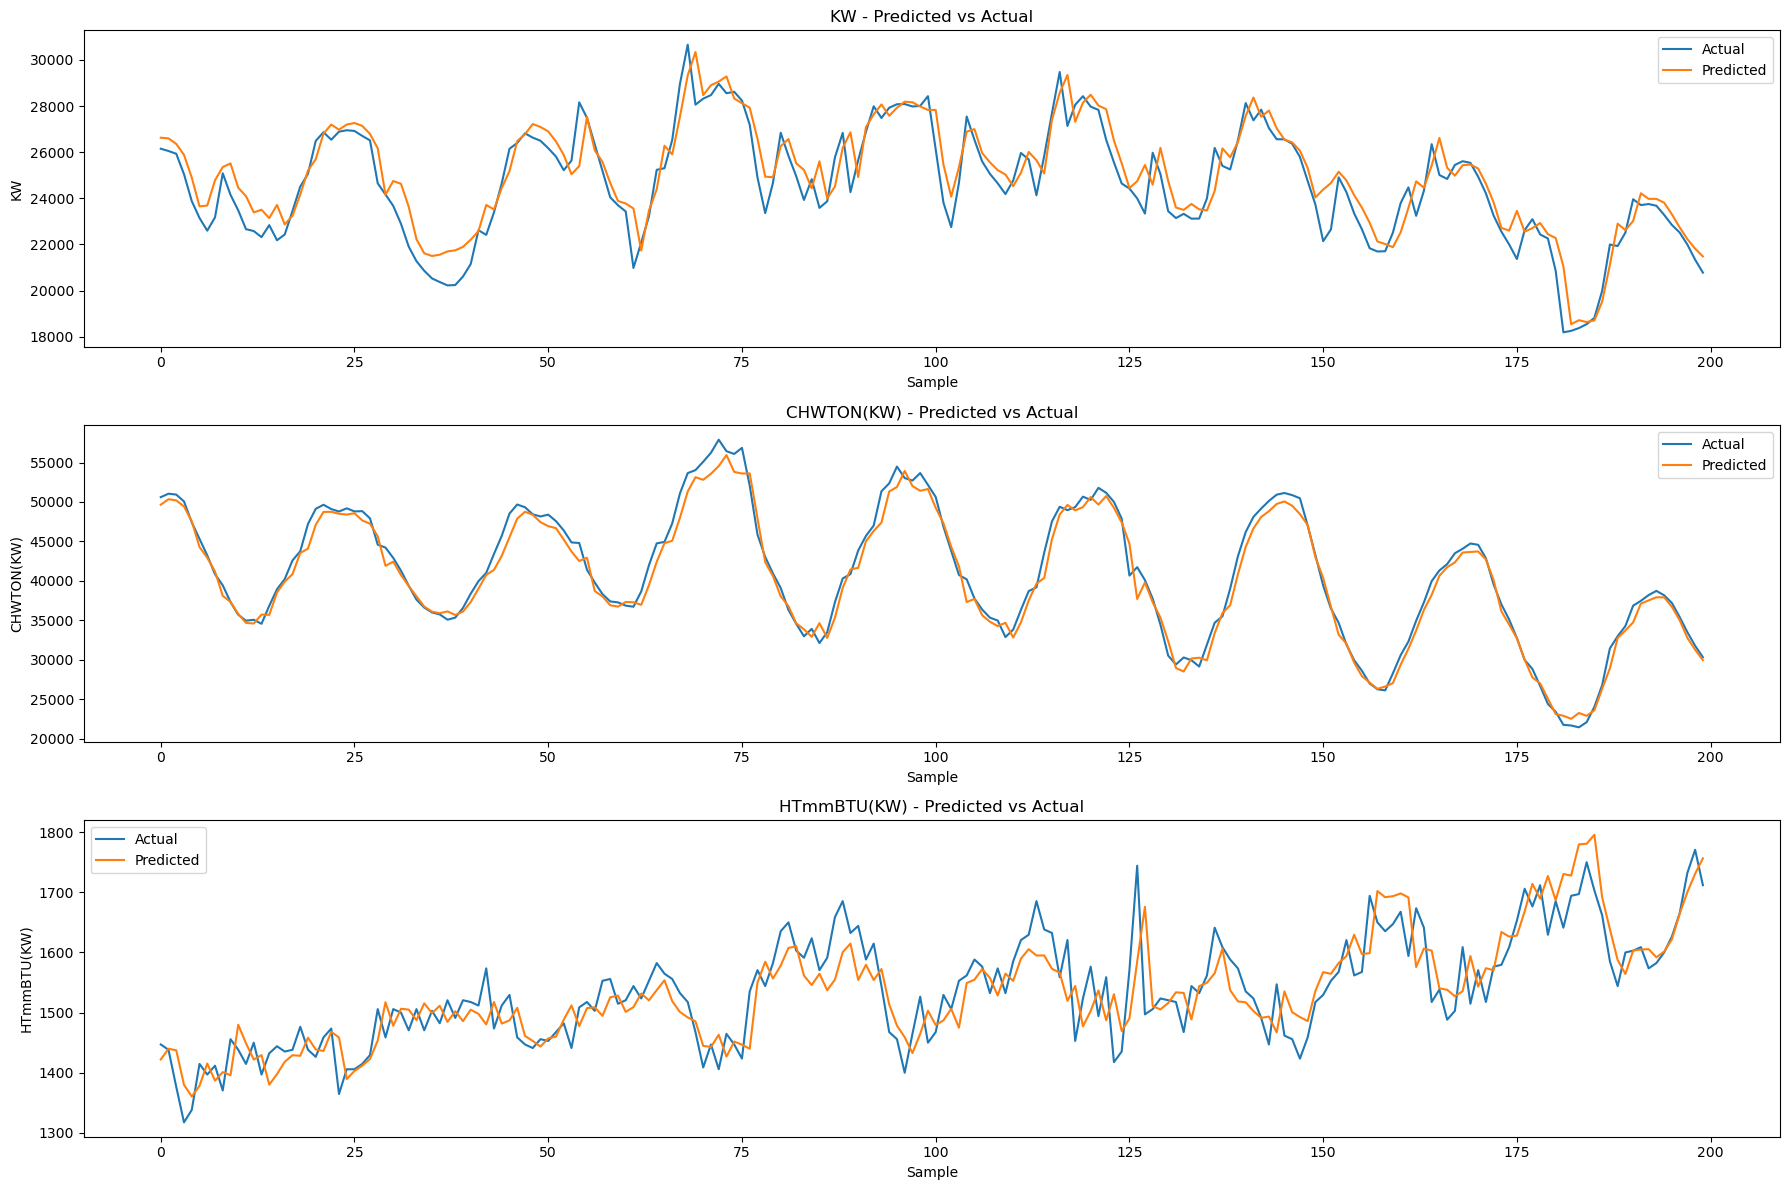

In [16]:
import matplotlib.pyplot as plt
import numpy as np

# Combine the inverse-transformed predictions and actual values
y_test_true = np.stack([y_test_kw, y_test_chw, y_test_ht], axis=1)
y_test_pred = np.stack([y_pred_kw, y_pred_chw, y_pred_ht], axis=1)

# Define labels
labels = ['KW', 'CHWTON(KW)', 'HTmmBTU(KW)']

# Plot first 200 samples for each target
plt.figure(figsize=(18, 12))
for i in range(3):
    plt.subplot(3, 1, i + 1)
    plt.plot(y_test_true[:200, i], label='Actual')
    plt.plot(y_test_pred[:200, i], label='Predicted')
    plt.title(f'{labels[i]} - Predicted vs Actual')
    plt.xlabel('Sample')
    plt.ylabel(labels[i])
    plt.legend()

plt.tight_layout()
plt.show()

In [17]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# Compute MAE and RMSE
def evaluate_predictions(y_true, y_pred, label):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    print(f'{label} - MAE: {mae:.2f}, RMSE: {rmse:.2f}')

evaluate_predictions(y_test_kw, y_pred_kw, 'KW')
evaluate_predictions(y_test_chw, y_pred_chw, 'CHWTON(KW)')
evaluate_predictions(y_test_ht, y_pred_ht, 'HTmmBTU(KW)')

KW - MAE: 452.82, RMSE: 656.39
CHWTON(KW) - MAE: 689.87, RMSE: 983.89
HTmmBTU(KW) - MAE: 77.22, RMSE: 103.69


In [18]:
def mean_absolute_percentage_error(y_true, y_pred):
    return np.mean(np.abs((y_true - y_pred) / y_true)) * 100

mape_kw = mean_absolute_percentage_error(y_test_kw, y_pred_kw)
mape_chw = mean_absolute_percentage_error(y_test_chw, y_pred_chw)
mape_ht = mean_absolute_percentage_error(y_test_ht, y_pred_ht)

print(f"KW MAPE: {mape_kw:.2f}%")
print(f"CHWTON MAPE: {mape_chw:.2f}%")
print(f"HTmmBTU MAPE: {mape_ht:.2f}%")


KW MAPE: 2.28%
CHWTON MAPE: 3.41%
HTmmBTU MAPE: 3.37%


In [19]:
import tensorflow as tf

# Define the custom weighted loss function
def custom_weighted_loss(y_true, y_pred):
    # Define weights for each output (adjust as needed)
    weights = tf.constant([1.0, 1.0, 1.0])  # Example weights for KW, CHWTON, HTmmBTU

    # Calculate squared errors for each output
    squared_errors = tf.square(y_true - y_pred)

    # Apply weights to the squared errors
    weighted_squared_errors = squared_errors * weights

    # Calculate the mean of the weighted squared errors
    loss = tf.reduce_mean(weighted_squared_errors)

    return loss

# Rebuild and compile the model with the custom loss function
model = build_multi_task_model(input_shape, output_dim)
model.compile(optimizer='adam', loss=custom_weighted_loss)


# Reshape y for training with custom loss
y_train_reshaped_custom_loss = y_train[:, 0, :]
y_val_reshaped_custom_loss = y_val[:, 0, :]

history = model.fit(X_train, y_train_reshaped_custom_loss,
                    validation_data=(X_val, y_val_reshaped_custom_loss),
                    epochs=50,
                    batch_size=64,
                    verbose=1)

Epoch 1/50
192/192 ━━━━━━━━━━━━━━━━━━━━ 8s 24ms/step - loss: 0.0034 - mae: 0.0384 - val_loss: 0.0041 - val_mae: 0.0491
Epoch 2/50
192/192 ━━━━━━━━━━━━━━━━━━━━ 4s 22ms/step - loss: 0.0012 - mae: 0.0256 - val_loss: 0.0027 - val_mae: 0.0365
Epoch 3/50
192/192 ━━━━━━━━━━━━━━━━━━━━ 4s 21ms/step - loss: 9.7382e-04 - mae: 0.0225 - val_loss: 0.0018 - val_mae: 0.0301
Epoch 4/50
192/192 ━━━━━━━━━━━━━━━━━━━━ 4s 22ms/step - loss: 8.6107e-04 - mae: 0.0211 - val_loss: 0.0019 - val_mae: 0.0315
Epoch 5/50
192/192 ━━━━━━━━━━━━━━━━━━━━ 4s 21ms/step - loss: 7.5326e-04 - mae: 0.0195 - val_loss: 0.0019 - val_mae: 0.0308
Epoch 6/50
192/192 ━━━━━━━━━━━━━━━━━━━━ 4s 23ms/step - loss: 6.9882e-04 - mae: 0.0188 - val_loss: 0.0019 - val_mae: 0.0346
Epoch 7/50
192/192 ━━━━━━━━━━━━━━━━━━━━ 5s 24ms/step - loss: 6.5473e-04 - mae: 0.0181 - val_loss: 0.0013 - val_mae: 0.0254
Epoch 8/50
192/192 ━━━━━━━━━━━━━━━━━━━━ 4s 23ms/step - loss: 6.3153e-04 - mae: 0.0177 - val_loss: 0.0012 - val_mae: 0.0244
Epoch 9/50
192/192 ━━━━━

***Tu construis ce modèle non pas seulement pour faire de la prédiction, mais surtout pour :

améliorer l’efficacité énergétique,

réduire les coûts,

anticiper les besoins (maintenance, optimisation),

et apporter une base solide à la prise de décision dans un contexte industriel ou bâtiment intelligent.

+Perte d’entraînement (loss) baisse progressivement → ton modèle apprend bien.

+Perte de validation (val_loss) baisse au début, puis stagne/remonte → à partir d’un certain point (vers epoch 15–20 ici), ton modèle mémorise trop l’entraînement et ne généralise plus parfaitement.

+Nombre optimal d’epochs : tu devrais probablement arrêter avant que val_loss commence à remonter (early stopping). Ici, ça semble être entre epoch 10 et 15.

In [20]:
import pandas as pd

# Charger les données
metro_data = pd.read_csv('data_set_adjusted.csv')

# S'assurer que la colonne datetime est bien au format datetime
metro_data['datetime'] = pd.to_datetime(metro_data['datetime'])

# Mettre datetime comme index (optionnel mais pratique)
metro_data = metro_data.set_index('datetime')

#  Ajout des colonnes temporelles utiles
metro_data['Hour'] = metro_data.index.hour
metro_data['DayOfWeek'] = metro_data.index.dayofweek
metro_data['Month'] = metro_data.index.month

# (Facultatif) Afficher pour vérifier
print(metro_data.head())

# PLUS BESOIN de faire :
# metro_data['Minute'] = ...
# metro_data = metro_data[metro_data['Minute'] != 30]

# Tu peux ensuite continuer la préparation du dataset :
# - normalisation / standardisation
# - création des séquences temporelles
# - split train / val / test

# Exemple : normalisation
from sklearn.preprocessing import StandardScaler

features = metro_data.columns  # toutes les colonnes sauf target, ou choisis celles que tu veux
scaler = StandardScaler()
metro_data_scaled = pd.DataFrame(scaler.fit_transform(metro_data),
                                 columns=features,
                                 index=metro_data.index)

# Vérifier
print(metro_data_scaled.head())

                           KW   CHWTON   CHWTON(KW)  HTmmBTU  HTmmBTU(KW)  \
datetime                                                                    
2018-01-01 00:00:00  17007.47  2021.27  7117.147887    13.17  3873.529412   
2018-01-01 01:00:00  16742.88  1841.30  6483.450704    15.24  4482.352941   
2018-01-01 02:00:00  16874.22  1772.96  6242.816901    16.36  4811.764706   
2018-01-01 03:00:00  16892.98  1736.67  6115.035211    16.03  4714.705882   
2018-01-01 04:00:00  16939.45  1706.68  6009.436620    15.63  4597.058824   

                     Combined mmBTU  Combined mmBTU(KW)     KW_PF  CHWTON_PF  \
datetime                                                                       
2018-01-01 00:00:00           95.46         28076.47059  0.605755   0.253492   
2018-01-01 01:00:00           94.46         27782.35294  0.602644   0.233366   
2018-01-01 02:00:00           95.22         28005.88235  0.602524   0.222911   
2018-01-01 03:00:00           94.51         27797.05882  0.6

In [21]:
data['Hour'] = data.index.hour
data['Day'] = data.index.dayofweek
data['Month'] = data.index.month
data['WeekOfYear'] = data.index.isocalendar().week.astype(int)
data['WeekOfYear_scaled'] = data['WeekOfYear'] / 52.0
data['Year'] = data.index.year

print(data.head())

                      CHWTON  HTmmBTU  Combined mmBTU  Combined mmBTU(KW)  \
datetime                                                                    
2018-01-01 00:00:00  2021.27    13.17           95.46         28076.47059   
2018-01-01 01:00:00  1841.30    15.24           94.46         27782.35294   
2018-01-01 02:00:00  1772.96    16.36           95.22         28005.88235   
2018-01-01 03:00:00  1736.67    16.03           94.51         27797.05882   
2018-01-01 04:00:00  1706.68    15.63           93.91         27620.58824   

                        KW_PF  CHWTON_PF  HTmmBTU_PF  DHI  DNI  GHI  ...  \
datetime                                                             ...   
2018-01-01 00:00:00  0.605755   0.253492    0.137964  0.0  0.0  0.0  ...   
2018-01-01 01:00:00  0.602644   0.233366    0.161338  0.0  0.0  0.0  ...   
2018-01-01 02:00:00  0.602524   0.222911    0.171813  0.0  0.0  0.0  ...   
2018-01-01 03:00:00  0.607725   0.219989    0.169612  0.0  0.0  0.0  ...   
2018

import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import KFold
import tensorflow as tf
import pandas as pd

# --- Paramètres ---
k = 5
kf = KFold(n_splits=k, shuffle=True, random_state=42)

val_losses = []
val_maes = []
epochs_per_fold = []

fold = 1
for train_index, val_index in kf.split(X):
    print(f"\n----- Fold {fold} / {k} -----")
    
    # Split des données
    X_train_fold, X_val_fold = X[train_index], X[val_index]
    y_train_fold, y_val_fold = y[train_index], y[val_index]

    # Reshape si besoin
    y_train_fold_reshaped = y_train_fold[:, 0, :]
    y_val_fold_reshaped = y_val_fold[:, 0, :]

    # Rebuild le modèle pour chaque fold
    model = build_multi_task_model(input_shape, output_dim)
    model.compile(optimizer='adam', loss='mse', metrics=['mae'])

    # Callback EarlyStopping
    early_stopping = tf.keras.callbacks.EarlyStopping(
        monitor='val_loss',
        patience=5,
        restore_best_weights=True
    )

    # Entraînement
    history = model.fit(
        X_train_fold, y_train_fold_reshaped,
        validation_data=(X_val_fold, y_val_fold_reshaped),
        epochs=50,
        batch_size=64,
        callbacks=[early_stopping],
        verbose=0
    )

    # Nombre d’epochs utilisés
    epochs_used = len(history.history['loss'])
    epochs_per_fold.append(epochs_used)

    # Évaluation finale
    val_loss, val_mae = model.evaluate(X_val_fold, y_val_fold_reshaped, verbose=0)
    val_losses.append(val_loss)
    val_maes.append(val_mae)

    print(f"Fold {fold} - val_loss: {val_loss:.4f}, val_mae: {val_mae:.4f}, epochs utilisés: {epochs_used}")
    fold += 1

# --- Résumé dans un tableau ---
results_df = pd.DataFrame({
    "Fold": range(1, k+1),
    "Val_Loss": val_losses,
    "Val_MAE": val_maes,
    "Epochs_Used": epochs_per_fold
})
print("\n===== Résultats Cross-Validation =====")
print(results_df)
print("\nMoyenne Val_Loss:", np.mean(val_losses), "±", np.std(val_losses))
print("Moyenne Val_MAE:", np.mean(val_maes), "±", np.std(val_maes))
print("Moyenne Epochs:", np.mean(epochs_per_fold), "±", np.std(epochs_per_fold))


*Que peut-on conclure concrètement ?

Si Val_Loss et Val_MAE sont faibles et proches des valeurs d’entraînement → modèle performant et bien généralise.

Si Val_Loss ou Val_MAE est plus élevé que sur le training → possible surapprentissage.

Si tu as plusieurs folds (cross-validation) :

Regarde la moyenne ± écart-type.

Une faible moyenne avec un écart-type faible → modèle robuste et stable.

Un écart-type élevé → performance inconstante selon les splits, ce qui peut signaler que le modèle est sensible aux données.

In [22]:
# Vérifier les valeurs uniques pour être sûr
print("Valeurs uniques de Day :", data['Day'].unique())

# Remplacer les 0 (ou valeurs invalides) par 1, qui est valide
data.loc[data['Day'] == 0, 'Day'] = 1

Valeurs uniques de Day : [0 1 2 3 4 5 6]


In [23]:
print(metro_data.columns)


Index(['KW', 'CHWTON', 'CHWTON(KW)', 'HTmmBTU', 'HTmmBTU(KW)',
       'Combined mmBTU', 'Combined mmBTU(KW)', 'KW_PF', 'CHWTON_PF',
       'HTmmBTU_PF', 'DHI', 'DNI', 'GHI', 'Dew Point', 'Wind Speed',
       'Precipitable Water', 'Wind Direction', 'Relative Humidity',
       'Temperature', 'Pressure', 'Hour', 'DayOfWeek', 'Month'],
      dtype='object')


In [24]:
data['Hour'] = data.index.hour
data['Day'] = data.index.dayofweek
data['Month'] = data.index.month
data['WeekOfYear'] = data.index.isocalendar().week.astype(int)
data['WeekOfYear_scaled'] = data['WeekOfYear'] / 52.0
data['Year'] = data.index.year

print(data.head())

                      CHWTON  HTmmBTU  Combined mmBTU  Combined mmBTU(KW)  \
datetime                                                                    
2018-01-01 00:00:00  2021.27    13.17           95.46         28076.47059   
2018-01-01 01:00:00  1841.30    15.24           94.46         27782.35294   
2018-01-01 02:00:00  1772.96    16.36           95.22         28005.88235   
2018-01-01 03:00:00  1736.67    16.03           94.51         27797.05882   
2018-01-01 04:00:00  1706.68    15.63           93.91         27620.58824   

                        KW_PF  CHWTON_PF  HTmmBTU_PF  DHI  DNI  GHI  ...  \
datetime                                                             ...   
2018-01-01 00:00:00  0.605755   0.253492    0.137964  0.0  0.0  0.0  ...   
2018-01-01 01:00:00  0.602644   0.233366    0.161338  0.0  0.0  0.0  ...   
2018-01-01 02:00:00  0.602524   0.222911    0.171813  0.0  0.0  0.0  ...   
2018-01-01 03:00:00  0.607725   0.219989    0.169612  0.0  0.0  0.0  ...   
2018

In [25]:
# Vérifier les valeurs uniques pour être sûr
print("Valeurs uniques de Day dans Data :", data['Day'].unique())

# Remplacer les 0 (ou valeurs invalides) par 1, qui est valide
data.loc[data['Day'] == 0, 'Day'] = 1

Valeurs uniques de Day dans Data : [0 1 2 3 4 5 6]


In [26]:
print(metro_data.columns)


Index(['KW', 'CHWTON', 'CHWTON(KW)', 'HTmmBTU', 'HTmmBTU(KW)',
       'Combined mmBTU', 'Combined mmBTU(KW)', 'KW_PF', 'CHWTON_PF',
       'HTmmBTU_PF', 'DHI', 'DNI', 'GHI', 'Dew Point', 'Wind Speed',
       'Precipitable Water', 'Wind Direction', 'Relative Humidity',
       'Temperature', 'Pressure', 'Hour', 'DayOfWeek', 'Month'],
      dtype='object')


In [27]:
print("Valeurs uniques de Day dans metro_data :", metro_data['DayOfWeek'].unique())
metro_data.loc[metro_data['DayOfWeek'] == 0, 'DayOfWeek'] = 1

Valeurs uniques de Day dans metro_data : [0 1 2 3 4 5 6]


In [28]:
metro_data['Hour'] = metro_data.index.hour
metro_data['Day'] = metro_data.index.dayofweek
metro_data['Month'] = metro_data.index.month
metro_data['WeekOfYear'] = metro_data.index.isocalendar().week.astype(int)
metro_data['WeekOfYear_scaled'] = metro_data['WeekOfYear'] / 52.0
metro_data['Year'] = metro_data.index.year

print(metro_data.head())

                           KW   CHWTON   CHWTON(KW)  HTmmBTU  HTmmBTU(KW)  \
datetime                                                                    
2018-01-01 00:00:00  17007.47  2021.27  7117.147887    13.17  3873.529412   
2018-01-01 01:00:00  16742.88  1841.30  6483.450704    15.24  4482.352941   
2018-01-01 02:00:00  16874.22  1772.96  6242.816901    16.36  4811.764706   
2018-01-01 03:00:00  16892.98  1736.67  6115.035211    16.03  4714.705882   
2018-01-01 04:00:00  16939.45  1706.68  6009.436620    15.63  4597.058824   

                     Combined mmBTU  Combined mmBTU(KW)     KW_PF  CHWTON_PF  \
datetime                                                                       
2018-01-01 00:00:00           95.46         28076.47059  0.605755   0.253492   
2018-01-01 01:00:00           94.46         27782.35294  0.602644   0.233366   
2018-01-01 02:00:00           95.22         28005.88235  0.602524   0.222911   
2018-01-01 03:00:00           94.51         27797.05882  0.6

In [29]:

print(metro_data.columns)

Index(['KW', 'CHWTON', 'CHWTON(KW)', 'HTmmBTU', 'HTmmBTU(KW)',
       'Combined mmBTU', 'Combined mmBTU(KW)', 'KW_PF', 'CHWTON_PF',
       'HTmmBTU_PF', 'DHI', 'DNI', 'GHI', 'Dew Point', 'Wind Speed',
       'Precipitable Water', 'Wind Direction', 'Relative Humidity',
       'Temperature', 'Pressure', 'Hour', 'DayOfWeek', 'Month', 'Day',
       'WeekOfYear', 'WeekOfYear_scaled', 'Year'],
      dtype='object')


In [30]:
# For data
data['datetime'] = data['Year'].astype(str) + '-' + \
                   data['Month'].astype(str).str.zfill(2) + '-' + \
                   data['Day'].astype(str).str.zfill(2) + '-' + \
                   data['Hour'].astype(str).str.zfill(2)

data['datetime'] = pd.to_datetime(data['datetime'], format='%Y-%m-%d-%H')

# For metro_data
metro_data['datetime'] = metro_data['Year'].astype(str) + '-' + \
                         metro_data['Month'].astype(str).str.zfill(2) + '-' + \
                         metro_data['DayOfWeek'].astype(str).str.zfill(2) + '-' + \
                         metro_data['Hour'].astype(str).str.zfill(2)

metro_data['datetime'] = pd.to_datetime(metro_data['datetime'], format='%Y-%m-%d-%H')

In [31]:
print(data.columns)


Index(['CHWTON', 'HTmmBTU', 'Combined mmBTU', 'Combined mmBTU(KW)', 'KW_PF',
       'CHWTON_PF', 'HTmmBTU_PF', 'DHI', 'DNI', 'GHI', 'Dew Point',
       'Wind Speed', 'Precipitable Water', 'Wind Direction',
       'Relative Humidity', 'Temperature', 'Pressure', 'KW', 'CHWTON(KW)',
       'HTmmBTU(KW)', 'Hour', 'Day', 'Month', 'WeekOfYear',
       'WeekOfYear_scaled', 'Year', 'datetime'],
      dtype='object')


In [32]:
data = data.set_index('datetime')
metro_data = metro_data.set_index('datetime')

In [33]:
data = data[['KW','HTmmBTU','CHWTON']]
Qu_1 = data.quantile(0.25)
Qu_3 = data.quantile(0.75)
IQR = Qu_3 - Qu_1
((data<(Qu_1 - 3.0 * IQR)) | (data>(Qu_3 + 2.0 * IQR))).sum()


KW          7
HTmmBTU    49
CHWTON      0
dtype: int64

In [34]:
data[((data < (Qu_1 - 2.0 * IQR)) | (data > (Qu_3 + 2.0 * IQR)))] = np.nan
data.loc[data['KW'] == 0, 'KW'] = np.nan
data.loc[data['HTmmBTU'] == 0, 'HTmmBTU'] = np.nan
data.loc[data['CHWTON'] == 0, 'CHWTON'] = np.nan

data.ffill(inplace=True)

In [35]:
merge=pd.merge(data,metro_data, how='inner', left_index=True, right_index=True)
print("Colonnes disponibles :", merge.columns.tolist())
    

Colonnes disponibles : ['KW_x', 'HTmmBTU_x', 'CHWTON_x', 'KW_y', 'CHWTON_y', 'CHWTON(KW)', 'HTmmBTU_y', 'HTmmBTU(KW)', 'Combined mmBTU', 'Combined mmBTU(KW)', 'KW_PF', 'CHWTON_PF', 'HTmmBTU_PF', 'DHI', 'DNI', 'GHI', 'Dew Point', 'Wind Speed', 'Precipitable Water', 'Wind Direction', 'Relative Humidity', 'Temperature', 'Pressure', 'Hour', 'DayOfWeek', 'Month', 'Day', 'WeekOfYear', 'WeekOfYear_scaled', 'Year']


In [36]:
data = merge
data['HTmmBTU_x'] = data['HTmmBTU_x'] * 293.07
data['CHWTON_x'] = data['CHWTON_x'] * 3.52

In [37]:
data['KW_last_hour'] = data['KW_x'].shift()
data['HTmmBTU_last_hour'] = data['HTmmBTU_x'].shift()
data['CHWTON_last_hour'] = data['CHWTON_x'].shift()

data['KW_last_2_hour'] = data['KW_x'].shift(2)
data['HTmmBTU_last_2_hour'] = data['HTmmBTU_x'].shift(2)
data['CHWTON_last_2_hour'] = data['CHWTON_x'].shift(2)

data['KW_last_day'] = data['KW_x'].shift(24)
data['HTmmBTU_last_day'] = data['HTmmBTU_x'].shift(24)
data['CHWTON_last_day'] = data['CHWTON_x'].shift(24)

data['KW_last_week'] = data['KW_x'].shift(168)
data['HTmmBTU_last_week'] = data['HTmmBTU_x'].shift(168)
data['CHWTON_last_week'] = data['CHWTON_x'].shift(168)

data['KW_last_year'] = data.groupby([data.index.month,data.index.day,data.index.hour])['KW_x'].shift()
data['HTmmBTU_last_year'] = data.groupby([data.index.month,data.index.day,data.index.hour])['HTmmBTU_x'].shift()
data['CHWTON_last_year'] = data.groupby([data.index.month,data.index.day,data.index.hour])['CHWTON_x'].shift()


data.bfill(inplace=True)

In [38]:
from sklearn.preprocessing import MinMaxScaler
import numpy as np
from numpy.lib.stride_tricks import sliding_window_view
import pandas as pd

# Extrait des données par saison
spring_data = data[(data['Month']>2) & (data['Month']<6)].copy()
spring_data.name = 'spring_data'

summer_data = data[(data['Month']>5) & (data['Month']<9)].copy()
summer_data.name = 'summer_data'

autumn_data = data[(data['Month']>8) & (data['Month']<12)].copy()
autumn_data.name = 'autumn_data'

winter_data = data[(data['Month']>11) | (data['Month']<3)].copy()
winter_data.name = 'winter_data'

# Renommer les colonnes pour qu'elles correspondent aux noms attendus
for df in [spring_data, summer_data, autumn_data, winter_data]:
    df.rename(columns={
        'KW_x': 'KW',
        'HTmmBTU_x': 'HTmmBTU',
        'CHWTON_x': 'CHWTON'
    }, inplace=True)

# --------------------------------------------------
# rolling_window (garde ta fonction actuelle)
def rolling_window(array_data_real, input_size, output_size, offset, out=[], inp=['C','H','E']):
    '''
    Découpe les données en fenêtres temporelles
    '''
    array_data = array_data_real.copy(deep=True)
    scaler = MinMaxScaler()
    scaler = scaler.fit(array_data)
    array_data_scaled = pd.DataFrame(scaler.transform(array_data), columns=array_data.columns)

    if ('C' not in inp) & ('C' not in out):
        array_data_scaled.drop(['CHWTON', 'CHWTON_last_hour', 'CHWTON_last_2_hour',
                                'CHWTON_last_day', 'CHWTON_last_week', 'CHWTON_last_year'], axis=1, inplace=True)
    if ('H' not in inp) & ('H' not in out):
        array_data_scaled.drop(['HTmmBTU', 'HTmmBTU_last_hour', 'HTmmBTU_last_2_hour',
                                'HTmmBTU_last_day', 'HTmmBTU_last_week', 'HTmmBTU_last_year'], axis=1, inplace=True)
    if ('E' not in inp) & ('E' not in out):
        array_data_scaled.drop(['KW', 'KW_last_hour', 'KW_last_2_hour',
                                'KW_last_day', 'KW_last_week', 'KW_last_year'], axis=1, inplace=True)
    data_idx = sliding_window_view(
        np.arange(array_data_scaled.shape[0]).reshape(-1),
        window_shape=input_size
    )[::offset][:-1]

    data = array_data_scaled.to_numpy()[data_idx]

    if 'C' in out:
        out_array = array_data_scaled['CHWTON'].to_numpy()
    elif 'H' in out:
        out_array = array_data_scaled['HTmmBTU'].to_numpy()
    elif 'E' in out:
        out_array = array_data_scaled['KW'].to_numpy()
    else:
        raise ValueError("Specify at least one output in 'out'.")

    labels = sliding_window_view(out_array[input_size:].reshape(-1), window_shape=output_size)[::offset]

    return data.astype(np.float64), labels.astype(np.float64), scaler, array_data        
        

In [39]:
##Autumn Data

tr_id = int((autumn_data.shape[0]*0.80)/24)*24
val_id = int((autumn_data.shape[0]*0.90)/24)*24
tra_data = autumn_data.iloc[:tr_id,:]
val_data = autumn_data.iloc[tr_id:val_id,:]
tes_data = autumn_data.iloc[val_id:,:]

In [40]:
heat_tra_data_sli,heat_tra_lab,heat_tra_sca,heat_tra_stan = rolling_window(tra_data,input_size=TRAIN_STEPS,output_size=OUTPUT_STEPS,offset=OFFSET,out=['H'],inp=['C','H','E'])
heat_val_data_sli,heat_val_lab,heat_val_sca,heat_val_stan = rolling_window(val_data,input_size=TRAIN_STEPS,output_size=OUTPUT_STEPS,offset=OFFSET,out=['H'],inp=['C','H','E'])
heat_tes_data_sli,heat_tes_lab,heat_test_scaler,heat_tes_stan = rolling_window(tes_data,input_size=TRAIN_STEPS,output_size=OUTPUT_STEPS,offset=OFFSET,out=['H'],inp=['C','H','E'])

## Cooling Data Summer

cool_tra_data_sli,cool_tra_lab,cool_tra_sca,col_tra_stan = rolling_window(tra_data,input_size=TRAIN_STEPS,output_size=OUTPUT_STEPS,offset=OFFSET,out=['C'],inp=['C','H','E'])
cool_val_data_sli,cool_val_lab,cool_val_sca,cool_val_stan = rolling_window(val_data,input_size=TRAIN_STEPS,output_size=OUTPUT_STEPS,offset=OFFSET,out=['C'],inp=['C','H','E'])
cool_tes_data_sli,cool_tes_lab,cool_test_scaler,cool_tes_stan = rolling_window(tes_data,input_size=TRAIN_STEPS,output_size=OUTPUT_STEPS,offset=OFFSET,out=['C'],inp=['C','H','E'])

## Electric Data Summer

elec_tra_data_sli,elec_tra_lab,elec_tra_sca,elec_tra_stan = rolling_window(tra_data,input_size=TRAIN_STEPS,output_size=OUTPUT_STEPS,offset=OFFSET,out=['E'],inp=['C','H','E'])
elec_val_data_sli,elec_val_lab,elec_val_sca,elec_val_stan = rolling_window(val_data,input_size=TRAIN_STEPS,output_size=OUTPUT_STEPS,offset=OFFSET,out=['E'],inp=['C','H','E'])
elec_tes_data_sli,elec_tes_lab,elec_test_scaler,elec_tes_stan = rolling_window(tes_data,input_size=TRAIN_STEPS,output_size=OUTPUT_STEPS,offset=OFFSET,out=['E'],inp=['C','H','E'])

In [41]:
def array_to_dataset(x1,y1,x2,y2,x3,y3,b_size):

    '''
    Takes inputs and labels for 3 different datasets and returns a dataloader object

    x1,y1 = heat

    x2,y2 = cool

    x3,y3 = elec
    '''

    x1_tensor = torch.from_numpy(x1).float()

    y1_tensor = torch.from_numpy(y1).float()

    x2_tensor = torch.from_numpy(x2).float()

    y2_tensor = torch.from_numpy(y2).float()

    x3_tensor = torch.from_numpy(x3).float()

    y3_tensor = torch.from_numpy(y3).float()

    dataset = TensorDataset(x1_tensor,y1_tensor,x2_tensor,y2_tensor,x3_tensor,y3_tensor)

    my_dataloader = DataLoader(dataset,batch_size=b_size)

    return my_dataloader

In [42]:
train_dataloader = array_to_dataset(heat_tra_data_sli,heat_tra_lab,cool_tra_data_sli,cool_tra_lab,elec_tra_data_sli,elec_tra_lab,b_size=BATCH_SIZE)
val_dataloader = array_to_dataset(heat_val_data_sli,heat_val_lab,cool_val_data_sli,cool_val_lab,elec_val_data_sli,elec_val_lab,b_size=BATCH_SIZE)
tes_dataloader = array_to_dataset(heat_tes_data_sli,heat_tes_lab,cool_tes_data_sli,cool_tes_lab,elec_tes_data_sli,elec_tes_lab,b_size=BATCH_SIZE)


In [43]:
class my_model(torch.nn.Module):

    def __init__(self, train_steps, heat_feature, cool_feature, elec_feature, lstm_dim):
        super().__init__()

        self.train_steps = train_steps
        self.heat_feature = heat_feature
        self.cool_feature = cool_feature
        self.elec_feature = elec_feature
        self.lstm_dim = lstm_dim

        self.input_1 = TCN(
            num_inputs=heat_feature,
            num_channels=[32, self.lstm_dim],
            kernel_size=8,
            dropout=0.2,
            input_shape='NLC',
            use_skip_connections=True,
            activation='leaky_relu'
        )

        self.input_2 = TCN(
            num_inputs=cool_feature,
            num_channels=[32, self.lstm_dim],
            kernel_size=8,
            dropout=0.2,
            input_shape='NLC',
            use_skip_connections=True,
            activation='leaky_relu'
        )

        self.input_3 = TCN(
            num_inputs=elec_feature,
            num_channels=[32, self.lstm_dim],
            kernel_size=8,
            dropout=0.2,
            input_shape='NLC',
            use_skip_connections=True,
            activation='leaky_relu'
        )
        self.flatten_layer = nn.Flatten(start_dim=1)
        self.fully = nn.Linear(3*self.lstm_dim, 3)
        self.relu = nn.LeakyReLU()

    def forward(self, heat_input, cool_input, elec_input):
        out_hea = self.input_1(heat_input)
        out_coo = self.input_2(cool_input)
        out_ele = self.input_3(elec_input)

        concat_layer = torch.cat((
            self.flatten_layer(out_hea[:, -1, :]),
            self.flatten_layer(out_coo[:, -1, :]),
            self.flatten_layer(out_ele[:, -1, :])
        ), 1)

        feature_sharing_layer = self.fully(concat_layer)
        final_output = self.relu(feature_sharing_layer)

        output_heat = final_output[:, 0].unsqueeze(1)
        output_cool = final_output[:, 1].unsqueeze(1)
        output_elec = final_output[:, 2].unsqueeze(1)

        return output_heat, output_cool, output_elec

HEA_FEA = int(heat_tra_data_sli.shape[2])
COO_FEA = int(cool_tra_data_sli.shape[2])
ELE_FEA = int(elec_tra_data_sli.shape[2])

In [44]:
from torchinfo import summary

model = my_model(TRAIN_STEPS, HEA_FEA, COO_FEA, ELE_FEA, LSTM_DIM)

summary(model, input_size=[
    (BATCH_SIZE, TRAIN_STEPS, HEA_FEA),   # heat_input
    (BATCH_SIZE, TRAIN_STEPS, COO_FEA),   # cool_input
    (BATCH_SIZE, TRAIN_STEPS, ELE_FEA)    # elec_input
])

Layer (type:depth-idx)                                       Output Shape              Param #
my_model                                                     [32, 1]                   --
├─TCN: 1-1                                                   [32, 168, 64]             --
│    └─ModuleList: 2-3                                       --                        (recursive)
│    │    └─TemporalBlock: 3-1                               [32, 32, 168]             21,312
│    └─ModuleList: 2-2                                       --                        --
│    │    └─Conv1d: 3-2                                      [32, 64, 168]             2,112
│    └─ModuleList: 2-3                                       --                        (recursive)
│    │    └─TemporalBlock: 3-3                               [32, 64, 168]             51,520
│    └─LeakyReLU: 2-4                                        [32, 64, 168]             --
├─TCN: 1-2                                                   [32, 

In [45]:
model = my_model(TRAIN_STEPS,HEA_FEA,COO_FEA,ELE_FEA,LSTM_DIM)
summary(model)

Layer (type:depth-idx)                                       Param #
my_model                                                     --
├─TCN: 1-1                                                   --
│    └─ModuleList: 2-1                                       --
│    │    └─Conv1d: 3-1                                      2,112
│    └─LeakyReLU: 2-2                                        --
│    └─ModuleList: 2-3                                       --
│    │    └─TemporalBlock: 3-2                               21,312
│    │    └─TemporalBlock: 3-3                               51,520
├─TCN: 1-2                                                   --
│    └─ModuleList: 2-4                                       --
│    │    └─Conv1d: 3-4                                      2,112
│    └─LeakyReLU: 2-5                                        --
│    └─ModuleList: 2-6                                       --
│    │    └─TemporalBlock: 3-5                               21,312
│    │    └─Tempo

In [46]:
def train_model(model,train_dataloader,val_dataloader,seq_length,n_epochs):

    history = dict(train=[],val=[])

    best_loss = 10000

    mb = master_bar(range(1,n_epochs+1))

    for epoch in mb:

        model = model.train()

        train_losses = []

        for TrainXHeat,TrainYHeat,TrainXCool,TrainYCool,TrainXElec,TrainYElec in tqdm(train_dataloader):

            seq_inp_heat = TrainXHeat.to(device)

            seq_true_heat = TrainYHeat.to(device)

            seq_inp_cool = TrainXCool.to(device)

            seq_true_cool = TrainYCool.to(device)

            seq_inp_elec = TrainXElec.to(device)

            seq_true_elec = TrainYElec.to(device)

            optimizer.zero_grad()

            seq_pred_heat,seq_pred_cool,seq_pred_elec = model(seq_inp_heat,seq_inp_cool,seq_inp_elec)

            loss_heat = criterion(seq_pred_heat,seq_true_heat)

            loss_cool = criterion(seq_pred_cool,seq_true_cool)


            loss_elec = criterion(seq_pred_elec,seq_true_elec)

            loss = loss_heat + loss_cool + loss_elec

            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1)

            optimizer.step()

            train_losses.append(loss.item())

        val_losses = []

        loss_cools = []

        loss_heats = []

        model = model.eval()

        with torch.no_grad():

            for ValidXHeat,ValidYHeat,ValidXCool,ValidYCool,ValidXElec,ValidYElec in val_dataloader:

                seq_inp_heat = ValidXHeat.to(device)

                seq_true_heat = ValidYHeat.to(device)

                seq_inp_cool = ValidXCool.to(device)

                seq_true_cool = ValidYCool.to(device)

                seq_inp_elec = ValidXElec.to(device)

                seq_true_elec = ValidYElec.to(device)

                seq_pred_heat,seq_pred_cool,seq_pred_elec = model(seq_inp_heat,seq_inp_cool,seq_inp_elec)

                loss_heat = criterion(seq_pred_heat,seq_true_heat)

                loss_cool = criterion(seq_pred_cool,seq_true_cool)

                loss_elec = criterion(seq_pred_elec,seq_true_elec)

                loss = loss_heat + loss_cool + loss_elec

                val_losses.append(loss.item())

                loss_cools.append(loss_cool.item())

                loss_heats.append(loss_heat.item())


        train_loss = np.mean(train_losses)

        val_loss = np.mean(val_losses)

        loss_cool_mean = np.mean(loss_cools)

        loss_heat_mean = np.mean(loss_heats)

        history['train'].append(train_loss)

        history['val'].append(val_loss)

        if val_loss < best_loss:

            best_loss = val_loss

            torch.save(model.state_dict(), 'best_model_n_features_GRU_1.pt')

            print("saved best model epoch:",epoch,"val loss is:",val_loss)

            print("cool val loss is:",loss_cool_mean)

            print("heat val loss is:",loss_heat_mean)



        print(f'Epoch {epoch}: train loss {train_loss} val loss {val_loss}')

        scheduler.step(val_loss)

    #model.load_state_dict(best_model_wts)

    return model.eval(), history                            

In [47]:
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4,weight_decay=1e-5)
criterion = torch.nn.MSELoss().to(device)
#scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max = 5e-3, eta_min=1e-8, last_epoch=-1)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer,  patience=10, factor =0.5 ,min_lr=1e-7, eps=1e-08)

In [ ]:
model, history = train_model(
  model,
  train_dataloader,
  val_dataloader,
  seq_length=TRAIN_STEPS,
  n_epochs=MAX_EPOCH, #Train for few epochs as illustration,

)

100%|██████████| 609/609 [03:08<00:00,  3.22it/s]


saved best model epoch: 1 val loss is: 0.14501710961728045
cool val loss is: 0.05095142735000183
heat val loss is: 0.051846207231897604
Epoch 1: train loss 0.045064496336740326 val loss 0.14501710961728045


100%|██████████| 609/609 [04:00<00:00,  2.53it/s]


saved best model epoch: 2 val loss is: 0.10860876168590039
cool val loss is: 0.04030180435478946
heat val loss is: 0.04349351803183607
Epoch 2: train loss 0.014803148875676695 val loss 0.10860876168590039


100%|██████████| 609/609 [05:10<00:00,  1.96it/s]


saved best model epoch: 3 val loss is: 0.0887861388683733
cool val loss is: 0.032670263142790645
heat val loss is: 0.03884974867186328
Epoch 3: train loss 0.009535145476362583 val loss 0.0887861388683733


... (67 outputs left out)

saved best model epoch: 37 val loss is: 0.018152038211054686
cool val loss is: 0.008215441343458628
heat val loss is: 0.00583518448466849
Epoch 37: train loss 0.0010427026769285104 val loss 0.018152038211054686


100%|██████████| 609/609 [01:35<00:00,  6.35it/s]


saved best model epoch: 38 val loss is: 0.017378187305035278
cool val loss is: 0.007714634331124317
heat val loss is: 0.005887645022691383
Epoch 38: train loss 0.0010345721857148958 val loss 0.017378187305035278


 49%|████▉     | 299/609 [45:14<02:13,  2.33it/s]    